# Homework 3: Machine Learning for Classification

Red Meigen Importante

## Setup

Download the dataset

In [8]:
data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'

# -nc means "no clobber": wget skips the download if the file already exists
!wget -nc -O data/lead_scoring_2026.csv $data

File ‘data/lead_scoring_2026.csv’ already there; not retrieving.


Load the data

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pprint import pprint

np.set_printoptions(suppress=True)

RANDOM_SEED = 42

df = pd.read_csv('data/lead_scoring_2026.csv')
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## EDA and Data Prep

### Check column info

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   lead_source               4852 non-null   str    
 1   industry                  4760 non-null   str    
 2   employment_status         4806 non-null   str    
 3   location                  4792 non-null   str    
 4   annual_income             4631 non-null   float64
 5   number_of_courses_viewed  5000 non-null   int64  
 6   interaction_count         5000 non-null   int64  
 7   lead_score                4965 non-null   float64
 8   converted                 5000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 351.7 KB


### Investigate the target variable

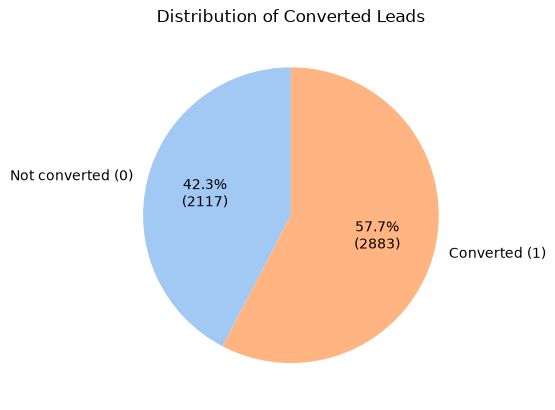

In [11]:
counts = df['converted'].value_counts().sort_index()

plt.pie(
    counts,
    labels=['Not converted (0)', 'Converted (1)'],
    autopct=lambda p: f'{p:.1f}%\n({int(round(p * counts.sum() / 100))})',
    startangle=90,
    colors=sns.color_palette('pastel')[:2],
)
plt.title('Distribution of Converted Leads')
plt.show()


**Insight:** Distribution is relatively balanced

### Spot missing values

If there are missing values:
* For categorical features, replace them with 'NA'
* For numerical features, replace with 0.0 

In [12]:
df.isnull().sum()

lead_source                 148
industry                    240
employment_status           194
location                    208
annual_income               369
number_of_courses_viewed      0
interaction_count             0
lead_score                   35
converted                     0
dtype: int64

### Extract the features

In [13]:
numerical = df.select_dtypes(include='number').columns.drop('converted').tolist()
categorical = df.select_dtypes(exclude='number').columns.tolist()

print('numerical:', numerical)
print('categorical:', categorical)

numerical: ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
categorical: ['lead_source', 'industry', 'employment_status', 'location']


### Clean the data

In [14]:
df_clean = df.copy()

df_clean[categorical] = df_clean[categorical].fillna('NA')
df_clean[numerical] = df_clean[numerical].fillna(0.0)

# Check again
df_clean.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [16]:
df_clean.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


## Question 1

What is the most frequent observation (mode) for the column `industry`?

In [17]:
df_clean['industry'].mode()[0]

'technology'

## Question 2

Create the [correlation matrix](https://www.google.com/search?q=correlation+matrix) for the numerical features of your dataset.
In a correlation matrix, you compute the correlation coefficient between every pair of features.

What are the two features that have the biggest correlation?

- `interaction_count` and `lead_score`
- `number_of_courses_viewed` and `lead_score`
- `number_of_courses_viewed` and `interaction_count`
- `annual_income` and `interaction_count`

Only consider the pairs above when answering this question.

In [18]:
corr = df_clean[numerical].corr()

# keep each pair once: take the upper triangle, excluding the diagonal
mask = np.triu(np.ones(corr.shape, dtype=bool), k=1)
pairs = corr.where(mask).stack().dropna()

pairs.abs().sort_values(ascending=False)


interaction_count         lead_score                  0.915746
number_of_courses_viewed  lead_score                  0.757204
                          interaction_count           0.721609
annual_income             lead_score                  0.229496
                          number_of_courses_viewed    0.161300
                          interaction_count           0.122842
dtype: float64

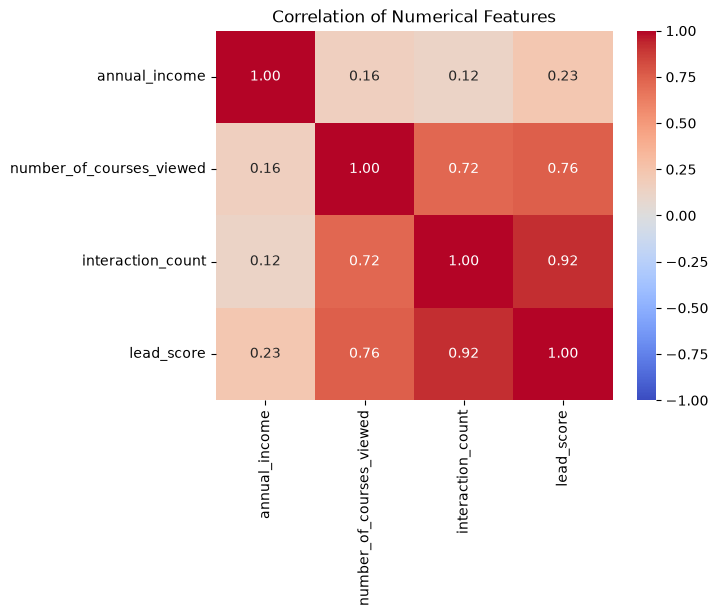

In [19]:
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation of Numerical Features')
plt.show()


## Split the data


In [20]:
from sklearn.model_selection import train_test_split

# Split the dataset into three partitions
df_full_train, df_test = train_test_split(
    df_clean, 
    test_size=0.2, 
    random_state=RANDOM_SEED
)

df_train, df_val = train_test_split(
    df_full_train, 
    test_size=0.25, 
    random_state=RANDOM_SEED
)

# Extract the targets
y_train = df_train['converted'].values
y_val = df_val['converted'].values
y_test = df_test['converted'].values

# Remove the targets from the feature matrixes
df_train = df_train.drop(columns='converted')
df_val = df_val.drop(columns='converted')
df_test = df_test.drop(columns='converted')

# Inspect the results
print('features:', df_train.shape, df_val.shape, df_test.shape)
print('targets: ', y_train.shape, y_val.shape, y_test.shape)
print('converted still in features:', 'converted' in df_train.columns)



features: (3000, 8) (1000, 8) (1000, 8)
targets:  (3000,) (1000,) (1000,)
converted still in features: False


## Question 3

- Calculate the mutual information score between `converted` and other categorical variables in the dataset. Use the training set only.
- Round the scores to 2 decimals using `round(score, 2)`.

Which of these variables has the biggest mutual information score?

- `industry`
- `location`
- `lead_source`
- `employment_status`

In [ ]:
from sklearn.metrics import mutual_info_score

mi = {col: mutual_info_score(df_train[col], y_train) for col in categorical}

mi_scores = pd.Series(mi).sort_values(ascending=False)
mi_scores.round(2)


lead_source          0.03
employment_status    0.02
industry             0.00
location             0.00
dtype: float64

## Question 4

- Now let's train a logistic regression.
- Remember that we have several categorical variables in the dataset. Include them using one-hot encoding.
- Fit the model on the training dataset.
  - To make sure the results are reproducible across different versions of Scikit-Learn, fit the model with these parameters:
  - `model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)`
- Calculate the accuracy on the validation dataset and round it to 2 decimal digits.

What accuracy did you get?

### One-hot encoding

Training set

In [23]:
train_dicts = df_train[categorical + numerical] \
    .to_dict(orient='records')

train_dicts[0]

{'lead_source': 'paid_ads',
 'industry': 'finance',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 65980.0,
 'number_of_courses_viewed': 2,
 'interaction_count': 3,
 'lead_score': 0.37}

In [27]:
from sklearn.feature_extraction import DictVectorizer

dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(train_dicts)

print(f'X_train shape: {X_train.shape}')
print()
print('Feature names:')
print(dv.get_feature_names_out())

X_train shape: (3000, 28)

Feature names:
['annual_income' 'employment_status=NA' 'employment_status=employed'
 'employment_status=self_employed' 'employment_status=student'
 'employment_status=unemployed' 'industry=NA' 'industry=education'
 'industry=finance' 'industry=healthcare' 'industry=manufacturing'
 'industry=retail' 'industry=technology' 'interaction_count' 'lead_score'
 'lead_source=NA' 'lead_source=events' 'lead_source=organic_search'
 'lead_source=paid_ads' 'lead_source=referral' 'lead_source=social_media'
 'location=NA' 'location=africa' 'location=asia' 'location=europe'
 'location=north_america' 'location=south_america'
 'number_of_courses_viewed']


In [ ]:
train_dicts = df_train[categorical + numerical] \
    .to_dict(orient='records')

train_dicts[0]

Validation set

In [28]:
val_dicts = df_val[categorical + numerical] \
    .to_dict(orient='records')

val_dicts[0]

{'lead_source': 'NA',
 'industry': 'technology',
 'employment_status': 'employed',
 'location': 'asia',
 'annual_income': 80457.0,
 'number_of_courses_viewed': 3,
 'interaction_count': 5,
 'lead_score': 0.64}

In [31]:
X_val = dv.transform(val_dicts)

print(f'X_val shape: {X_val.shape}')

X_val shape: (1000, 28)


### Training the model

In [32]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    solver='liblinear',
    C=1.0,
    max_iter=1000,
    random_state=RANDOM_SEED)

model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l

### Generate predictions

In [38]:
y_pred = model.predict(X_val)

accuracy = (y_pred == y_val).mean()

print(f'Validation accuracy: {round(accuracy, 2)}')

Validation accuracy: 0.64


### Question 5

- Let's find the least useful feature using the _feature elimination_ technique.
- Train a model using the same features and parameters as in Q4 (without rounding).
- Now exclude each feature from this set and train a model without it. Record the accuracy for each model.
- For each feature, calculate the difference between the original accuracy and the accuracy without the feature.

Which of following feature has the smallest difference?

- `'lead_source'`
- `'number_of_courses_viewed'`
- `'interaction_count'`

> **Note**: The difference doesn't have to be positive.

In [40]:
def train_and_score(feats):
    dv = DictVectorizer(sparse=False)

    X_train = dv.fit_transform(df_train[feats].to_dict(orient='records'))
    X_val = dv.transform(df_val[feats].to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=RANDOM_SEED)
    model.fit(X_train, y_train)

    return float((model.predict(X_val) == y_val).mean())


features = categorical + numerical
baseline = train_and_score(features)
print(f'Baseline accuracy: {baseline:.4f}')

results = []
for feature in features:
    feats_without = [x for x in features if x != feature]
    accuracy = train_and_score(feats_without)
    results.append({
        'dropped': feature, 
        'accuracy': accuracy, 
        'difference': baseline - accuracy
    })

df_results = pd.DataFrame(results)
df_results['abs_difference'] = df_results['difference'].abs()

df_results.sort_values('abs_difference')


Baseline accuracy: 0.6450


,dropped,accuracy,difference,abs_difference
1,industry,0.645,0.000,0.000
2,employment_status,0.645,0.000,0.000
3,location,0.645,0.000,0.000
7,lead_score,0.644,0.001,0.001
5,number_of_courses_viewed,0.643,0.002,0.002
0,lead_source,0.642,0.003,0.003
6,interaction_count,0.601,0.044,0.044
4,annual_income,0.724,-0.079,0.079


### Question 6

- Now let's train a regularized logistic regression.
- Let's try the following values of the parameter `C`: `[0.000001, 0.00001, 0.0001, 0.001]`.
- Train models using all the features as in Q4.
- Calculate the accuracy on the validation dataset and round it to 3 decimal digits.

Which of these `C` leads to the best accuracy on the validation set?

- 0.000001
- 0.00001
- 0.0001
- 0.001

> **Note**: If there are multiple options, select the smallest `C`.

In [42]:
C_values = [0.000001, 0.00001, 0.0001, 0.001]
results = []

for C in C_values:
    model = LogisticRegression(
        solver='liblinear',
        C=C,
        max_iter=1000,
        random_state=RANDOM_SEED)

    model.fit(X_train, y_train)

    accuracy = float((model.predict(X_val) == y_val).mean())
    results.append({'C': C, 'accuracy': round(accuracy, 3)})

# rank by accuracy (best first); ties go to the smaller C
df_c = (
    pd.DataFrame(results)
    .sort_values(['accuracy', 'C'], ascending=[False, True])
    .reset_index(drop=True)
)

df_c

,C,accuracy
0,0.001000,0.645
1,0.000100,0.613
2,0.000001,0.598
3,0.000010,0.598


In [43]:
# the top row is the answer
best = df_c.iloc[0]
print(f"Best accuracy: {best['accuracy']}, best C: {best['C']}")

Best accuracy: 0.645, best C: 0.001
